# The transit gap and the unreached tracts: New York and Houston

05.3 and 05.3.1 routed the LODES commutes between the kept tracts of each area by car, bicycle,
e-bike and transit, and 05.4 compared the modes. This notebook looks at two things on the map. First
the gap between transit and the car: for each commute reached by both, the transit time divided by
the car time at the morning rush, with cafein's intersection delays, summarised per home tract.
Second the commutes that transit does not reach at all: which home tracts and which work tracts
they belong to, with the routing point of every tract drawn on top, since a point placed away
from where people live or work is one of the suspects. The last step writes down, in order, how
those points were placed.

| Step | What we do |
|---|---|
| 1. Inputs | The OD tables with travel times, the kept tracts, and the routing points before and after snapping, for both areas |
| 2. The gap | Transit minutes over car minutes per commute, the worker-weighted median per home tract, one map per area on the same scale |
| 3. The unreached | The share of each tract's resident workers, and of its jobs, with no transit itinerary, one figure per area with the routing points drawn |
| 4. The routing points | How the point of each tract was placed, step by step, and where that can go wrong |


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch


## 1. Inputs

One OD table per area, with a row per pair of tracts that has a flow between routing points, its
workers and its travel times in minutes, missing when the mode does not reach the pair. The car
time used here is the one with intersection delays at the rush profile, as in 05.4. The routing
points come in two files: the point placed from the blocks (05.3 step 3) and the same point moved
onto a street inside its tract (05.3 step 5); the distance between the two is kept for the maps.


In [2]:
YEAR = 2023
RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
AREAS = {
    "New York": {"folder": RESULTS / "new-york", "departure": "2026-10-20 08:30", "metric_crs": "EPSG:32618", "zoom": 9},
    "Houston": {"folder": RESULTS / "houston", "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32615", "zoom": 10},
    "Chicago": {"folder": RESULTS / "chicago", "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32616", "zoom": 9},
    "Seattle": {"folder": RESULTS / "seattle", "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32610", "zoom": 10},
    "Phoenix": {"folder": RESULTS / "phoenix", "departure": "2026-11-10 08:30", "metric_crs": "EPSG:32612", "zoom": 10},
}

od = {}
tracts = {}
points = {}
for area, spec in AREAS.items():
    od[area] = pd.read_parquet(spec["folder"] / "matrices" / f"tract-od-times-{YEAR}.parquet")
    tracts[area] = gpd.read_parquet(spec["folder"] / f"tracts-kept-{YEAR}.parquet")
    placed = gpd.read_parquet(spec["folder"] / f"tract-points-{YEAR}.parquet").set_index("id")
    snapped = gpd.read_parquet(spec["folder"] / f"tract-points-snapped-{YEAR}.parquet").set_index("id")
    shift = placed.geometry.to_crs(spec["metric_crs"]).distance(snapped.geometry.to_crs(spec["metric_crs"]).reindex(placed.index))
    points[area] = gpd.GeoDataFrame({"tract": snapped.index, "shift_m": shift.reindex(snapped.index).round(0).to_numpy()},
                                    geometry=snapped.geometry.to_numpy(), crs="EPSG:4326")
    print(f"{area}: {len(od[area]):,} tract pairs, {od[area]['workers'].sum():,} workers, {len(tracts[area]):,} tracts kept, "
          f"{len(points[area]):,} routing points, transit at {spec['departure']}")


New York: 2,408,240 tract pairs, 6,708,932 workers, 4,589 tracts kept, 4,588 routing points, transit at 2026-10-20 08:30
Houston: 608,199 tract pairs, 2,114,670 workers, 1,447 tracts kept, 1,445 routing points, transit at 2026-11-10 08:30
Chicago: 933,646 tract pairs, 3,423,828 workers, 2,153 tracts kept, 2,153 routing points, transit at 2026-11-10 08:30


Seattle: 253,835 tract pairs, 1,531,980 workers, 791 tracts kept, 791 routing points, transit at 2026-11-10 08:30
Phoenix: 386,194 tract pairs, 1,748,052 workers, 1,008 tracts kept, 1,008 routing points, transit at 2026-11-10 08:30


## 2. The gap between transit and the car

For every commute that both transit and the car reach, the gap is the transit time divided by the
car time: 1 means transit is as fast as driving, 2 means it takes twice as long. Commutes inside one
tract are left out, because both times are zero there. The map shows, per home tract, the
worker-weighted median of that ratio over the tract's residents, so the colour says how much
longer the typical resident's commute takes by transit than by car. The classes and colours are
the same in both areas, so the same colour means the same ratio in New York and in Houston; the
legend sits below the map and county lines are drawn for orientation. Tracts in grey have no
resident whose commute both modes reach. The table first gives the worker-weighted distribution
over all such commutes in each area.


In [3]:
def weighted_percentile(values, weights, percentile):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return values[order][np.searchsorted(cumulative, percentile / 100)]


def weighted_median_by(table, by, value, weight):
    # Worker-weighted median of `value` within each group, without a Python loop over groups.
    ordered = table.sort_values([by, value])
    total = ordered.groupby(by)[weight].transform("sum")
    cumulative = ordered.groupby(by)[weight].cumsum()
    return ordered.loc[cumulative >= total / 2].groupby(by)[value].first()


gap = {}
per_tract = {}
rows = []
for area, table in od.items():
    both = table.loc[table["transit_min"].notna() & (table["car_min"] > 0) & (table["from_id"] != table["to_id"])].copy()
    both["ratio"] = both["transit_min"] / both["car_min"]
    gap[area] = both
    ratio, weights = both["ratio"].to_numpy(), both["workers"].to_numpy()
    rows.append({
        "area": area,
        "commutes reached by both, share of workers": weights.sum() / table["workers"].sum(),
        "median ratio": weighted_percentile(ratio, weights, 50),
        "p25 ratio": weighted_percentile(ratio, weights, 25),
        "p75 ratio": weighted_percentile(ratio, weights, 75),
        "share with transit at most as slow as the car": weights[ratio <= 1].sum() / weights.sum(),
        "share with transit at least twice as slow": weights[ratio >= 2].sum() / weights.sum(),
        "share with transit at least three times as slow": weights[ratio >= 3].sum() / weights.sum(),
    })
    per_tract[area] = pd.DataFrame({
        "residents": table.groupby("from_id")["workers"].sum(),
        "residents reached by both": both.groupby("from_id")["workers"].sum(),
        "median ratio": weighted_median_by(both, "from_id", "ratio", "workers"),
        "median transit minutes": weighted_median_by(both, "from_id", "transit_min", "workers"),
        "median car minutes": weighted_median_by(both, "from_id", "car_min", "workers"),
    }).rename_axis("tract").reset_index()
print("transit minutes over car minutes at the rush, commutes between different tracts reached by both, worker-weighted:")
pd.DataFrame(rows).set_index("area").T.round(2)


transit minutes over car minutes at the rush, commutes between different tracts reached by both, worker-weighted:


area,New York,Houston,Chicago,Seattle,Phoenix
"commutes reached by both, share of workers",0.88,0.29,0.64,0.82,0.58
median ratio,2.20,2.80,2.31,2.35,2.98
p25 ratio,1.75,2.37,1.86,2.00,2.46
p75 ratio,2.89,3.35,3.04,2.83,3.57
share with transit at most as slow as the car,0.00,0.00,0.00,0.00,0.00
share with transit at least twice as slow,0.61,0.91,0.67,0.75,0.92
share with transit at least three times as slow,0.22,0.39,0.26,0.19,0.49


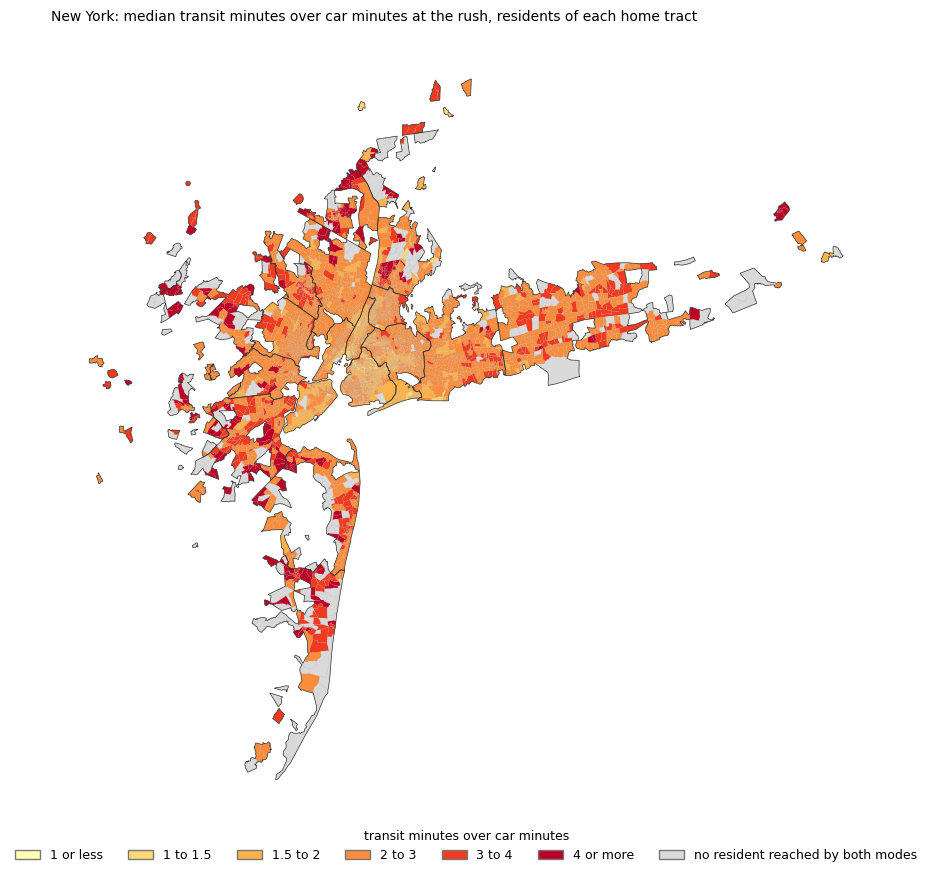

In [4]:
GAP_BINS = [0, 1, 1.5, 2, 3, 4, np.inf]
GAP_COLOURS = ["#ffffb2", "#fed976", "#feb24c", "#fd8d3c", "#f03b20", "#bd0026"]
GAP_LABELS = ["1 or less", "1 to 1.5", "1.5 to 2", "2 to 3", "3 to 4", "4 or more"]
MISSING_COLOUR = "#d9d9d9"


def class_colours(values, bins, colours):
    # One colour per row from its class; rows without a value are grey.
    index = pd.cut(values, bins, right=False, labels=False)
    return [MISSING_COLOUR if np.isnan(i) else colours[int(i)] for i in index]


def draw_classes(axis, area, shown, column, bins, colours, title):
    spec = AREAS[area]
    metric = shown.to_crs(spec["metric_crs"])
    metric.plot(ax=axis, color=class_colours(metric[column], bins, colours), edgecolor="#9a9a9a", linewidth=0.08)
    counties[area].plot(ax=axis, color="#333333", linewidth=0.5)
    axis.set_title(title, loc="left", fontsize=10)
    axis.set_aspect("equal")
    axis.set_axis_off()


def class_legend(figure, colours, labels, missing_label, title, ncol):
    handles = [Patch(facecolor=colour, edgecolor="#777777", label=label) for colour, label in zip(colours, labels)]
    handles.append(Patch(facecolor=MISSING_COLOUR, edgecolor="#777777", label=missing_label))
    figure.legend(handles=handles, loc="outside lower center", ncol=ncol, frameon=False, title=title, fontsize=9, title_fontsize=9)


counties = {area: tracts[area].to_crs(AREAS[area]["metric_crs"]).dissolve("NAMELSADCO").boundary for area in AREAS}


def gap_map(area):
    shown = tracts[area][["tract", "geometry"]].merge(per_tract[area], on="tract", how="left")
    figure, axis = plt.subplots(figsize=(10, 9), layout="constrained")
    figure.get_layout_engine().set(rect=(0, 0, 1, 0.96))
    draw_classes(axis, area, shown, "median ratio", GAP_BINS, GAP_COLOURS,
                 f"{area}: median transit minutes over car minutes at the rush, residents of each home tract")
    class_legend(figure, GAP_COLOURS, GAP_LABELS, "no resident reached by both modes", "transit minutes over car minutes", ncol=7)
    figure.savefig(FIGURES / f"05.6-transit-gap-{area.lower().replace(' ', '-')}.png", dpi=150)
    return figure


gap_map("New York");


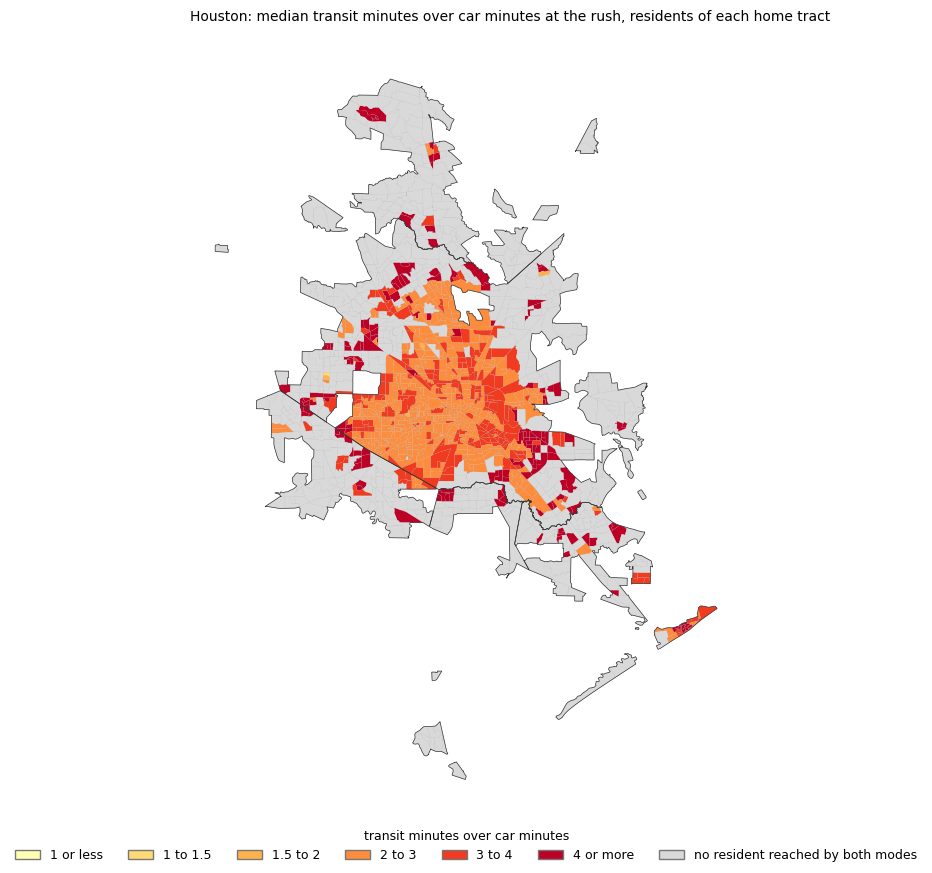

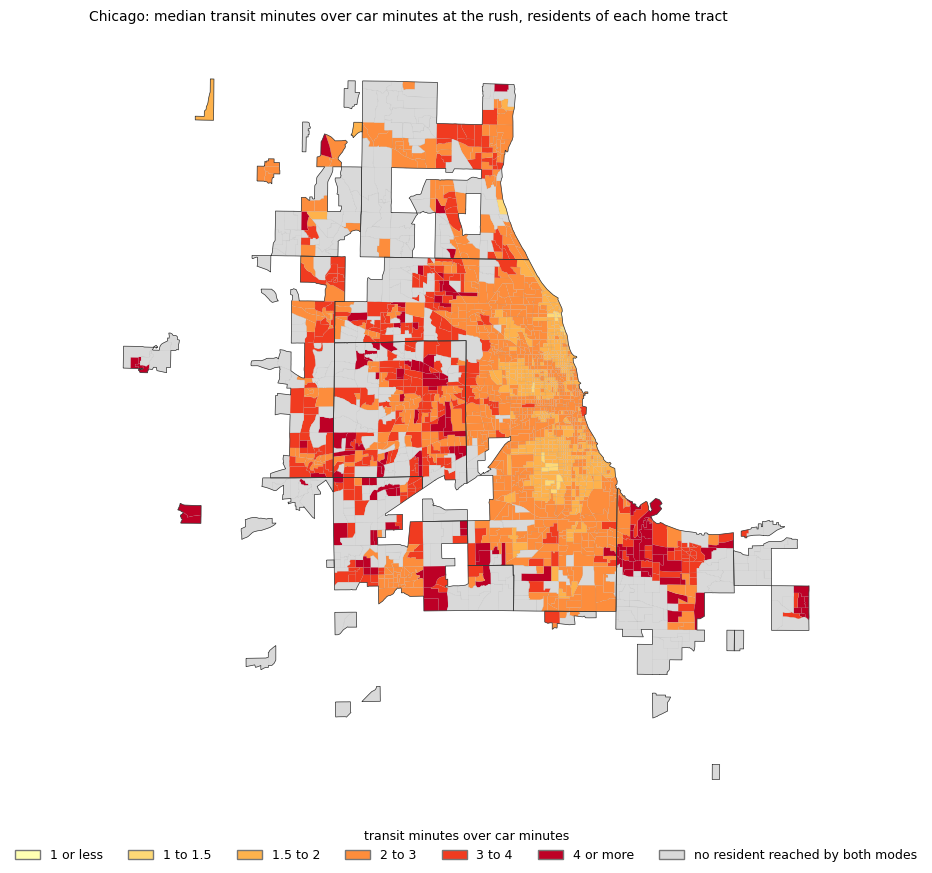

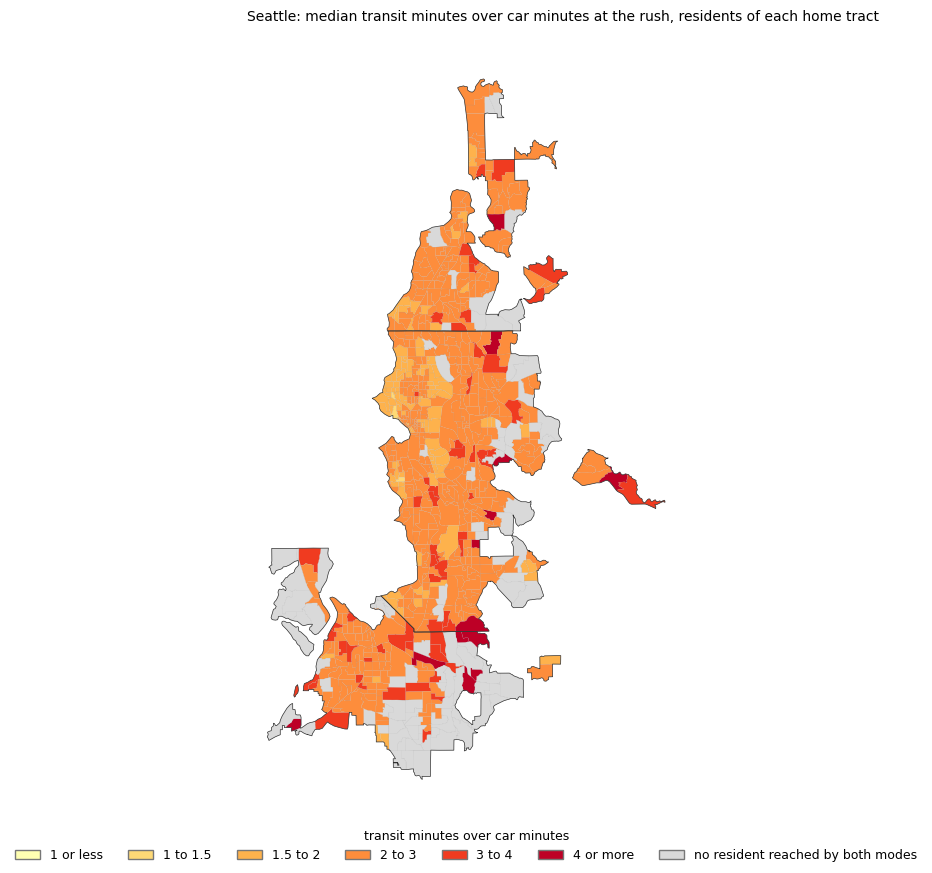

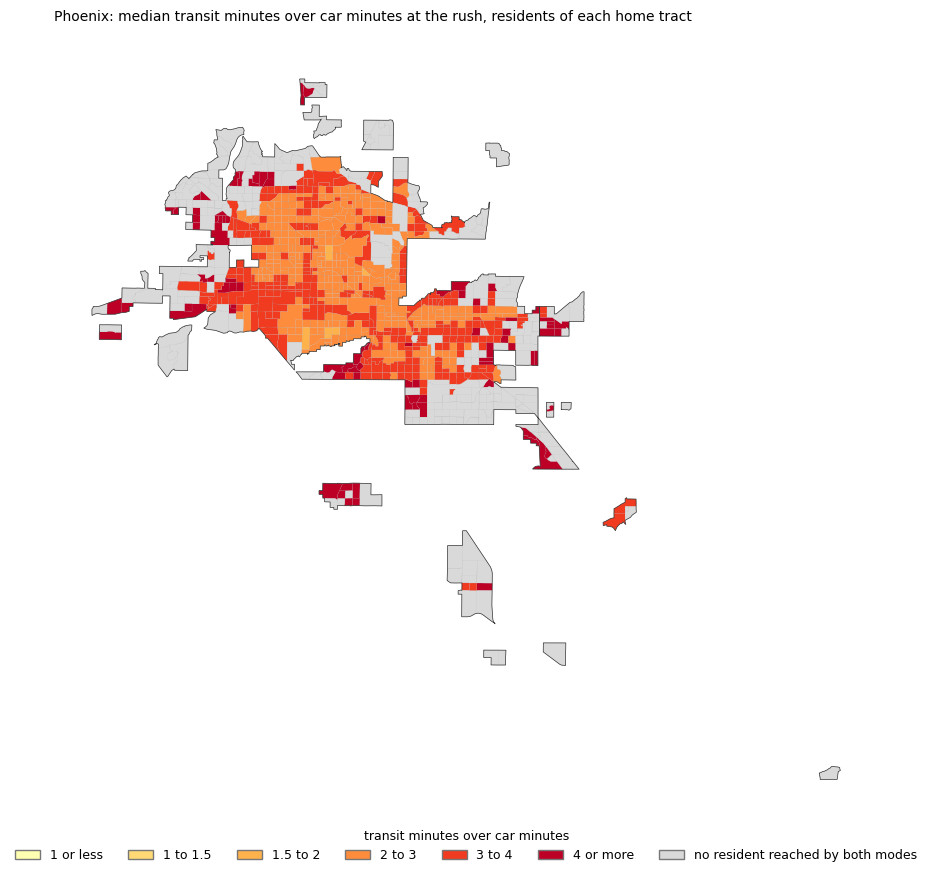

In [5]:
gap_map("Houston");
gap_map("Chicago");
gap_map("Seattle");
gap_map("Phoenix");


## 3. The tracts transit does not reach

A commute is unreached when it has no transit itinerary for the departure, whatever the reason:
no stop within reach of the home or the work point, or no sequence of rides between them that
morning (05.3.1 step 13 takes Houston apart by cause). Here the unreached commutes are counted at
each end: per home tract, the share of its resident workers with no itinerary, and per work tract,
the share of the jobs there whose holder has none. The two readings are the two panels of one
figure per area, on the same classes and colours in both areas. The routing point of every tract
is drawn as a black dot, so a point sitting in an empty corner of a large tract can be spotted
against the tract outlines. The tables list the areas side by side and the home tracts carrying
the most unreached workers, with the distance each point was moved to reach a street.


In [6]:
unreached = {}
rows = []
for area, table in od.items():
    missing = table.loc[table["transit_min"].isna()]
    home = pd.DataFrame({"residents": table.groupby("from_id")["workers"].sum(),
                         "residents unreached": missing.groupby("from_id")["workers"].sum()}).fillna(0).rename_axis("tract")
    work = pd.DataFrame({"jobs": table.groupby("to_id")["workers"].sum(),
                         "jobs unreached": missing.groupby("to_id")["workers"].sum()}).fillna(0).rename_axis("tract")
    per = home.join(work, how="outer").fillna(0)
    per["share of residents unreached"] = per["residents unreached"] / per["residents"]
    per["share of jobs unreached"] = per["jobs unreached"] / per["jobs"]
    unreached[area] = per.reset_index()
    rows.append({
        "area": area,
        "workers unreached": missing["workers"].sum(),
        "share of all workers": missing["workers"].sum() / table["workers"].sum(),
        "home tracts with every resident unreached": int((per["residents unreached"] == per["residents"]).loc[per["residents"] > 0].sum()),
        "home tracts with no resident unreached": int((per["residents unreached"] == 0).loc[per["residents"] > 0].sum()),
        "work tracts with every job unreached": int((per["jobs unreached"] == per["jobs"]).loc[per["jobs"] > 0].sum()),
    })
print("commutes with no transit itinerary:")
display(pd.DataFrame(rows).set_index("area").T)

for area in AREAS:
    largest = unreached[area].merge(tracts[area][["tract", "NAMELSADCO", "land_km2"]], on="tract").nlargest(10, "residents unreached")
    largest = largest.merge(points[area][["tract", "shift_m"]], on="tract", how="left")
    print(f"{area}: the ten home tracts with the most unreached workers")
    display(largest[["tract", "NAMELSADCO", "land_km2", "residents", "residents unreached", "share of residents unreached", "share of jobs unreached", "shift_m"]]
            .round({"land_km2": 1, "share of residents unreached": 2, "share of jobs unreached": 2}).reset_index(drop=True))


commutes with no transit itinerary:


area,New York,Houston,Chicago,Seattle,Phoenix
workers unreached,616218.00000,1.444625e+06,1.118498e+06,234528.000000,691752.000000
share of all workers,0.09185,6.831444e-01,3.266805e-01,0.153088,0.395727
home tracts with every resident unreached,10.00000,5.000000e+00,2.000000e+00,0.000000,4.000000
home tracts with no resident unreached,43.00000,0.000000e+00,0.000000e+00,0.000000,0.000000
work tracts with every job unreached,7.00000,5.000000e+00,2.000000e+00,0.000000,4.000000


New York: the ten home tracts with the most unreached workers


,tract,NAMELSADCO,land_km2,residents,residents unreached,share of residents unreached,share of jobs unreached,shift_m
0,36081045500,Queens County,0.1,4456,4424.0,0.99,0.99,2.0
1,34039038601,Union County,7.8,3265,3169.0,0.97,0.92,1.0
2,36059519500,Nassau County,2.0,2707,2605.0,0.96,0.94,3.0
3,36103159108,Suffolk County,7.6,2712,2591.0,0.96,0.93,38.0
4,34023001504,Middlesex County,3.6,2543,2459.0,0.97,0.97,30.0
5,34027043401,Morris County,7.9,2475,2434.0,0.98,0.93,134.0
6,36103146800,Suffolk County,3.1,2513,2429.0,0.97,0.93,30.0
7,34035053105,Somerset County,5.3,2444,2390.0,0.98,0.93,19.0
8,34013021602,Essex County,7.9,2467,2384.0,0.97,0.90,17.0
9,36119010500,Westchester County,4.5,2647,2356.0,0.89,0.89,25.0


Houston: the ten home tracts with the most unreached workers


,tract,NAMELSADCO,land_km2,residents,residents unreached,share of residents unreached,share of jobs unreached,shift_m
0,48157672901,Fort Bend County,13.0,6697,6461,0.96,0.87,11.0
1,48157675502,Fort Bend County,19.0,6466,6329,0.98,0.92,13.0
2,48201250408,Harris County,10.9,6139,6068,0.99,0.85,21.0
3,48157672903,Fort Bend County,9.7,6008,5941,0.99,0.94,2.0
4,48201543006,Harris County,12.1,5935,5836,0.98,0.91,17.0
5,48339692009,Montgomery County,9.9,5463,5357,0.98,0.88,58.0
6,48157673108,Fort Bend County,15.8,5729,5155,0.90,0.96,4.0
7,48339692008,Montgomery County,14.8,4684,4589,0.98,0.85,12.0
8,48157673201,Fort Bend County,10.7,4633,4532,0.98,0.81,7.0
9,48157674702,Fort Bend County,16.6,4537,4420,0.97,0.90,47.0


... (2 outputs left out)

Seattle: the ten home tracts with the most unreached workers


,tract,NAMELSADCO,land_km2,residents,residents unreached,share of residents unreached,share of jobs unreached,shift_m
0,53061052107,Snohomish County,12.5,3569,3514,0.98,0.92,128.0
1,53061052607,Snohomish County,10.2,3251,3234,0.99,0.95,3.0
2,53053071412,Pierce County,6.8,2776,2741,0.99,0.93,60.0
3,53061041704,Snohomish County,4.0,2811,2731,0.97,0.97,110.0
4,53033032215,King County,16.0,2779,2729,0.98,0.91,20.0
5,53053070315,Pierce County,9.8,2670,2606,0.98,0.31,1.0
6,53053070313,Pierce County,13.9,2652,2598,0.98,0.91,28.0
7,53061051926,Snohomish County,8.5,2602,2563,0.99,0.97,128.0
8,53033029304,King County,4.2,2565,2547,0.99,0.84,36.0
9,53053071310,Pierce County,6.5,2565,2545,0.99,0.93,20.0


Phoenix: the ten home tracts with the most unreached workers


,tract,NAMELSADCO,land_km2,residents,residents unreached,share of residents unreached,share of jobs unreached,shift_m
0,04013050612,Maricopa County,17.1,5135,5086,0.99,0.71,33.0
1,04013422647,Maricopa County,10.2,4314,4213,0.98,0.86,44.0
2,04013061053,Maricopa County,6.0,4197,4105,0.98,0.96,23.0
3,04013061011,Maricopa County,16.2,4063,4012,0.99,0.94,10.0
4,04021001709,Pinal County,5.2,4228,4009,0.95,0.58,30.0
5,04013061052,Maricopa County,5.1,3642,3610,0.99,0.93,7.0
6,04013082211,Maricopa County,4.1,3538,3517,0.99,0.94,11.0
7,04021000224,Pinal County,3.8,3525,3492,0.99,0.72,43.0
8,04021000212,Pinal County,11.3,3453,3408,0.99,0.79,40.0
9,04013812400,Maricopa County,16.5,3483,3377,0.97,0.99,8.0


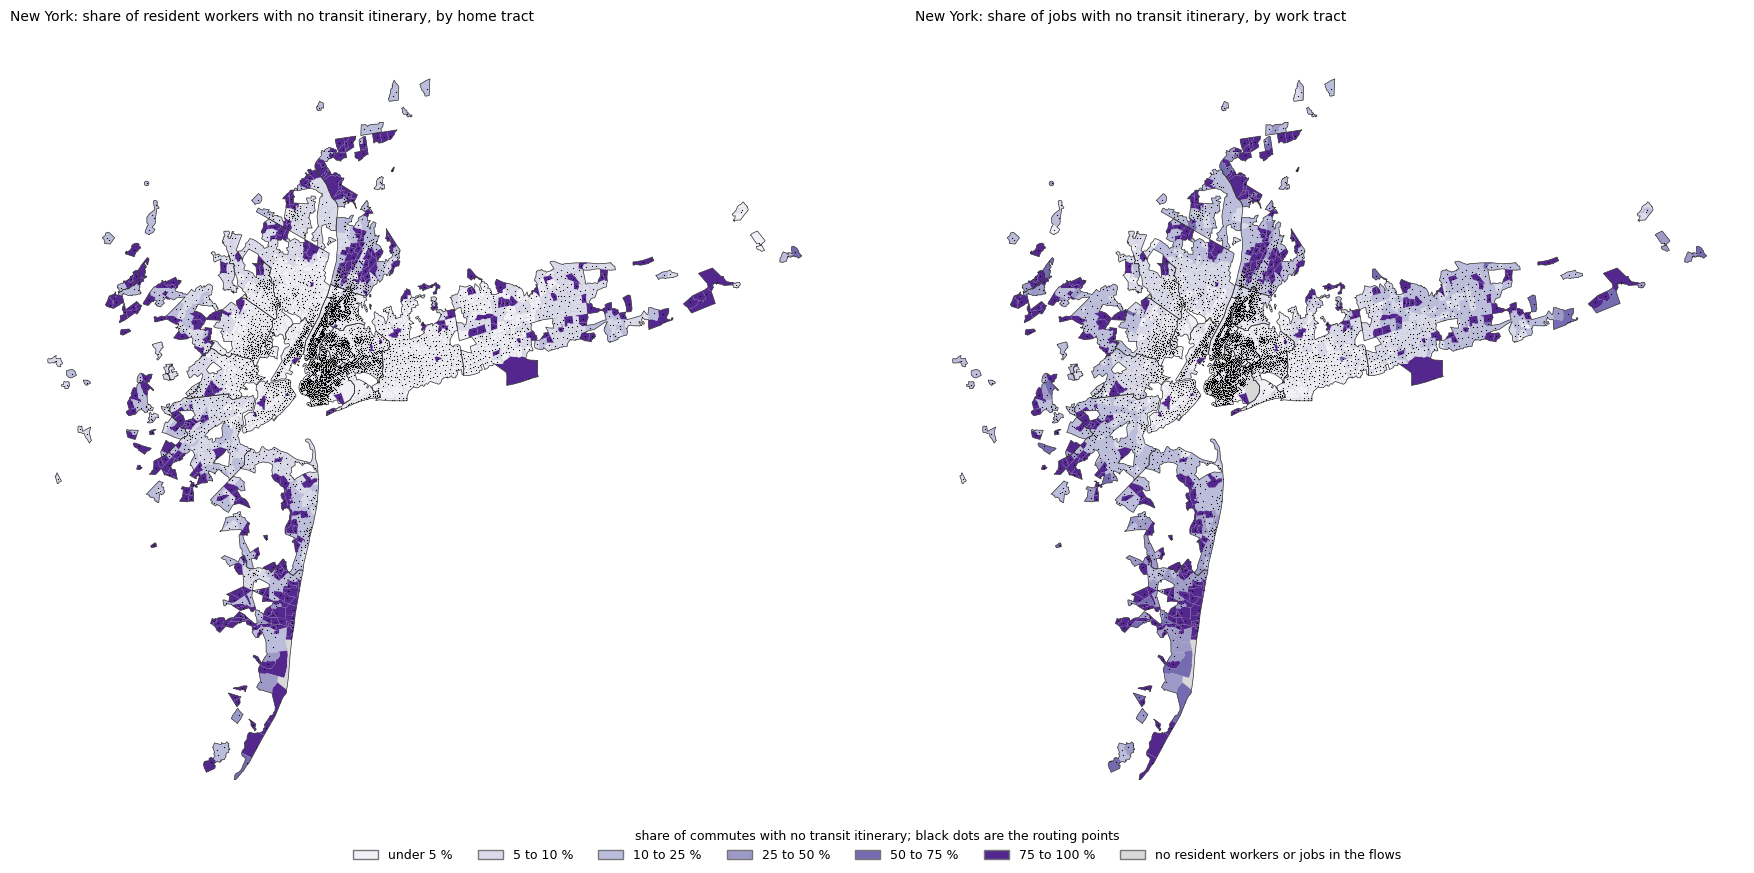

In [7]:
UNREACHED_BINS = [0, 0.05, 0.1, 0.25, 0.5, 0.75, 1.0000001]
UNREACHED_COLOURS = ["#f2f0f7", "#dadaeb", "#bcbddc", "#9e9ac8", "#756bb1", "#54278f"]
UNREACHED_LABELS = ["under 5 %", "5 to 10 %", "10 to 25 %", "25 to 50 %", "50 to 75 %", "75 to 100 %"]


def unreached_map(area):
    shown = tracts[area][["tract", "geometry"]].merge(unreached[area], on="tract", how="left")
    dots = points[area].to_crs(AREAS[area]["metric_crs"])
    figure, axes = plt.subplots(ncols=2, figsize=(18, 9), layout="constrained")
    figure.get_layout_engine().set(rect=(0, 0, 1, 0.96))
    draw_classes(axes[0], area, shown, "share of residents unreached", UNREACHED_BINS, UNREACHED_COLOURS,
                 f"{area}: share of resident workers with no transit itinerary, by home tract")
    draw_classes(axes[1], area, shown, "share of jobs unreached", UNREACHED_BINS, UNREACHED_COLOURS,
                 f"{area}: share of jobs with no transit itinerary, by work tract")
    for axis in axes:
        dots.plot(ax=axis, color="black", markersize=0.8, linewidth=0)
    class_legend(figure, UNREACHED_COLOURS, UNREACHED_LABELS, "no resident workers or jobs in the flows",
                 "share of commutes with no transit itinerary; black dots are the routing points", ncol=7)
    figure.savefig(FIGURES / f"05.6-unreached-{area.lower().replace(' ', '-')}.png", dpi=150)
    return figure


unreached_map("New York");


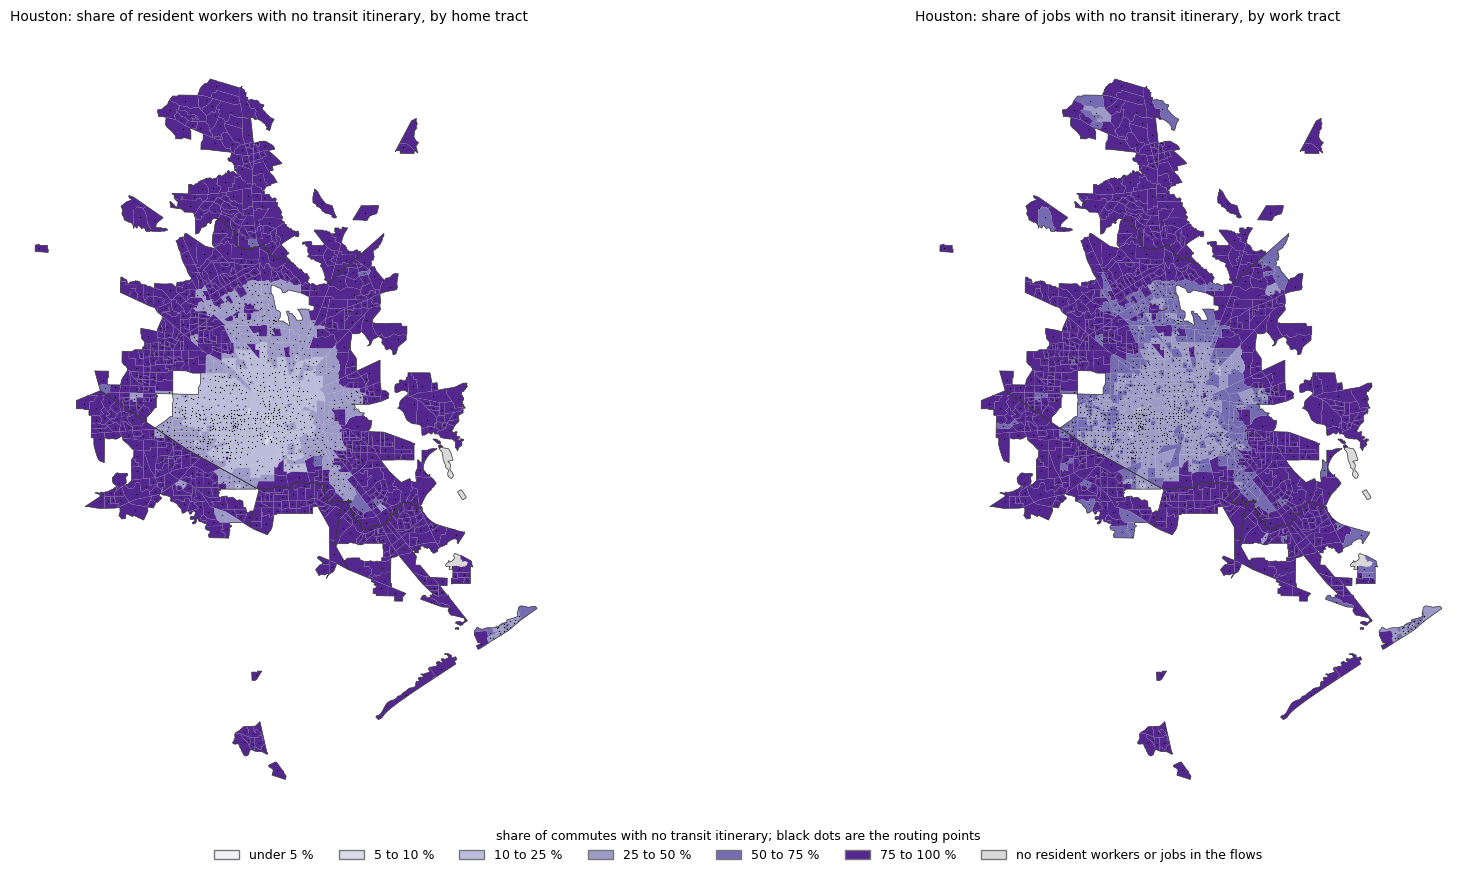

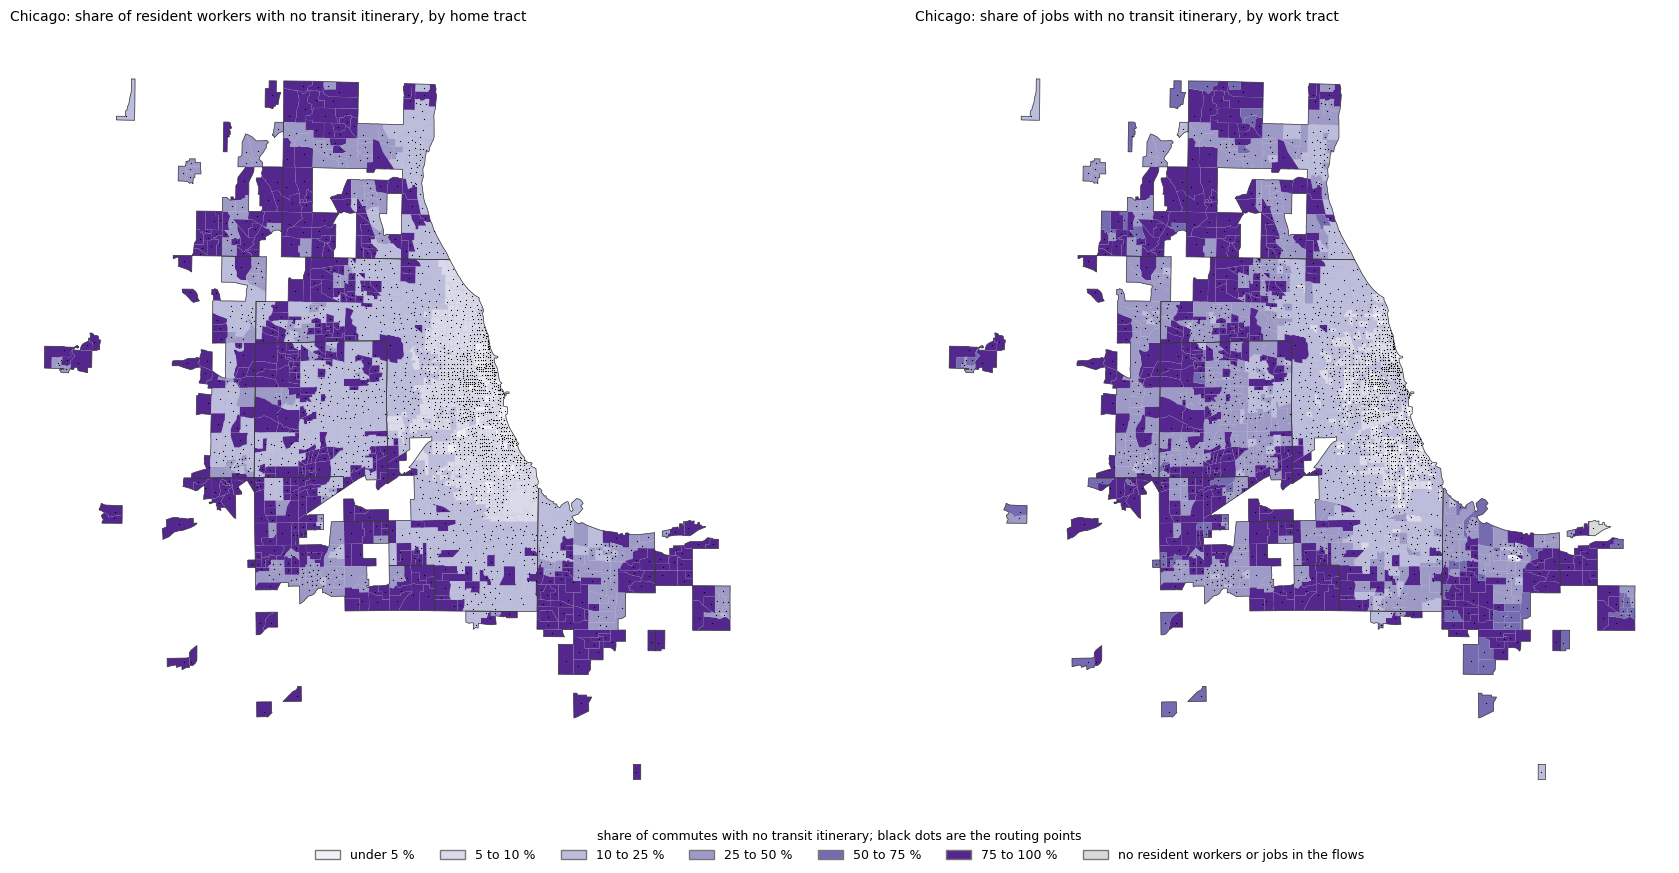

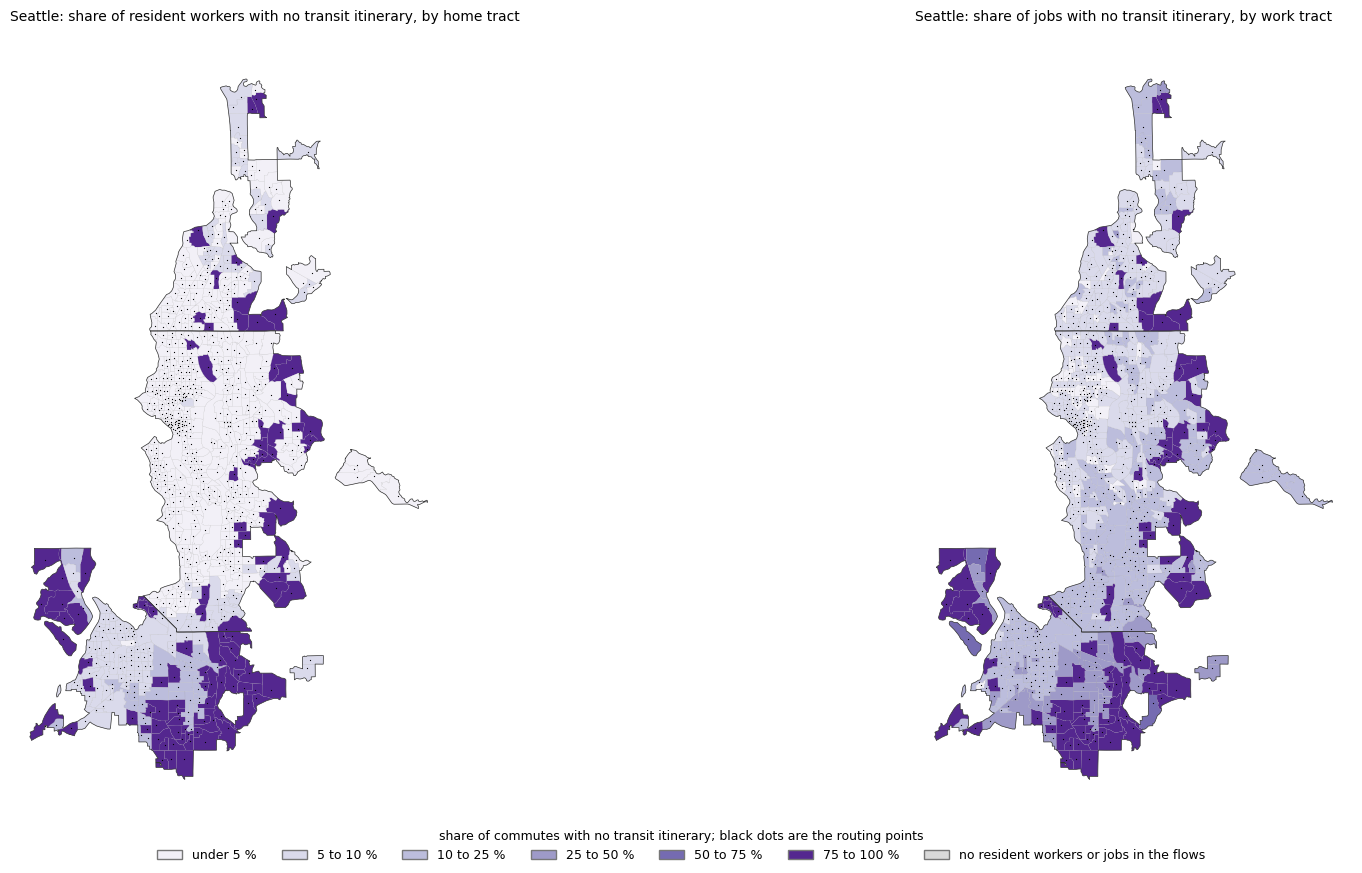

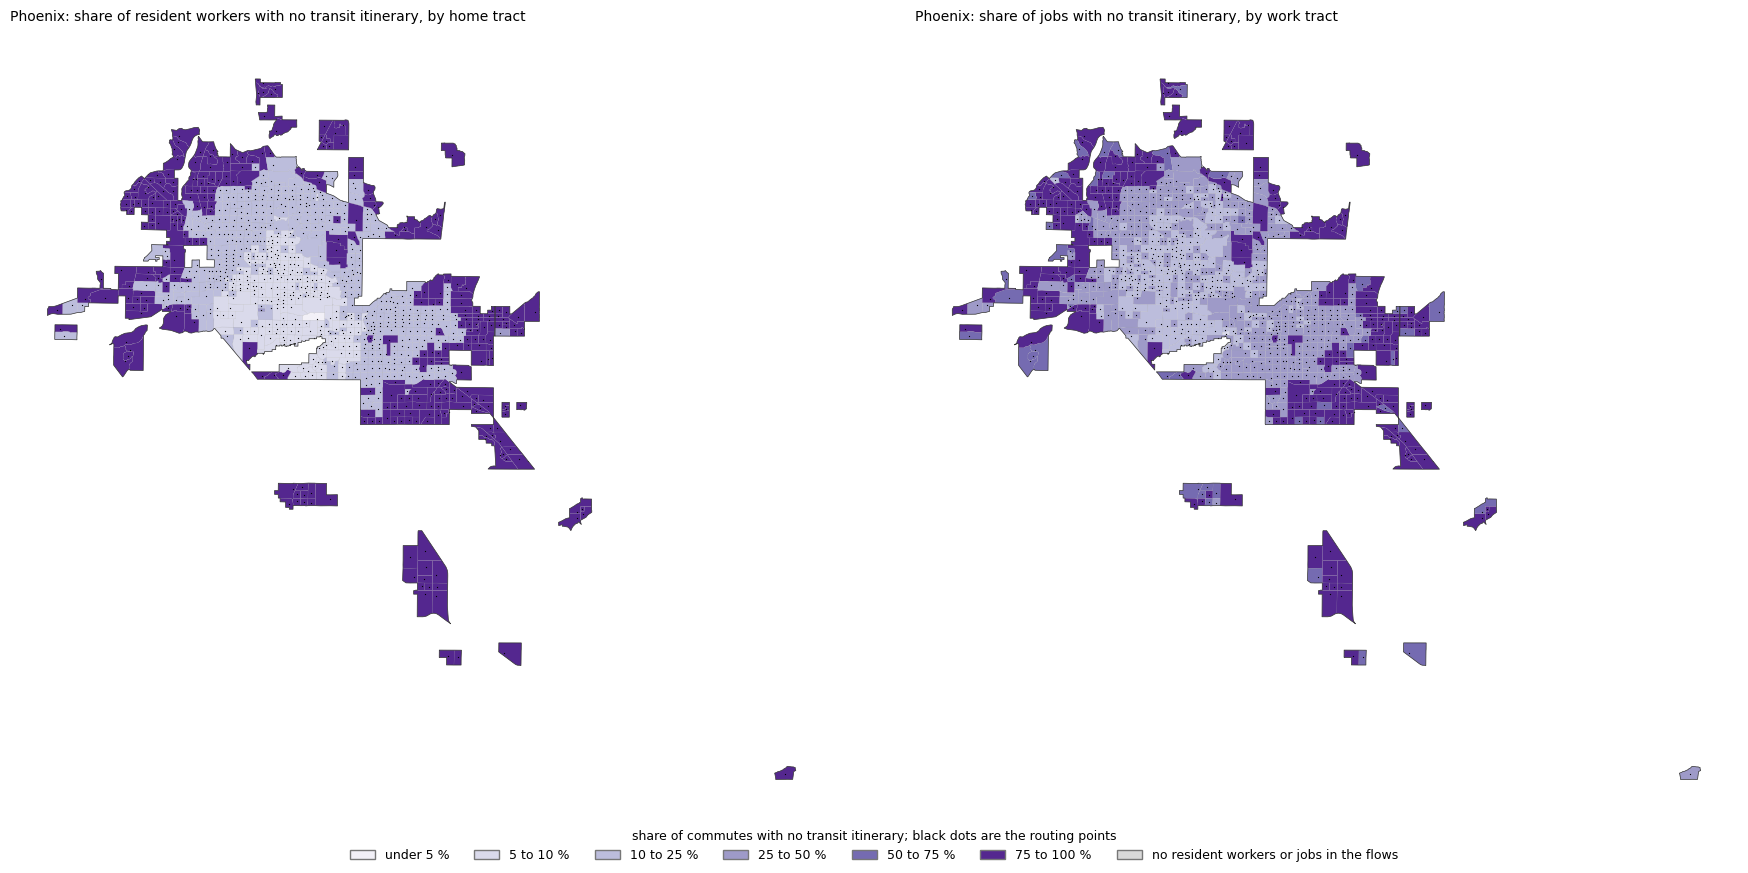

In [8]:
unreached_map("Houston");
unreached_map("Chicago");
unreached_map("Seattle");
unreached_map("Phoenix");


## 4. How the routing point of each tract was placed

The routing goes from one point per home tract to one point per work tract. This is how that
point was chosen in 05.3 and 05.3.1, in order:

1. **Start from the blocks.** LODES gives every commute at block level, and the Census gives every
   block an internal point, a coordinate inside the block. The kept home-to-work flows are summed
   by home block, so each block has a count of resident workers.
2. **Average the block points, weighted by resident workers.** The point of a tract is the mean of
   its blocks' internal points, each block counting as many times as it has resident workers.
   Blocks where nobody in the flows lives do not pull the point at all, so it lands where the
   tract's commuters live rather than at the geometric middle of the polygon.
3. **Fall back to a representative point when that fails.** If the tract has no resident worker in
   the kept flows, or if the weighted mean falls outside the tract's own polygon (a crescent or a
   tract in several pieces can do that), the point is the polygon's representative point, a
   point guaranteed to lie inside it.
4. **Move the point onto a street inside the tract.** Routing has to start on the street network,
   so the point is moved to the nearest edge of the cafein network that lies inside the tract,
   and only if that edge is within 1,000 m; otherwise the tract gets no routing point and its
   flows are dropped. New York lost one tract this way and Houston none. The move is usually
   short: the median is a few tens of metres.
5. **Use that one point at both ends.** The same point is the origin of the tract's residents
   and the destination of the tract's jobs.

Two things in this recipe can place a point where it should not be. The weighting uses where
people **live**, so for the work end of a commute the point can sit in a residential corner of a
tract whose jobs are somewhere else, for instance a tract with housing on one side and an
industrial park or a hospital on the other; a second point per tract weighted by jobs, from the
same LODES file summed by work block, would fix that with no new data. And a tract with few
resident workers spread over a large area gets a point that may lie between its settled parts,
in a field or a reservoir, a kilometre or more from any street with a bus stop; the Houston
unreached tracts of 05.3.1, median 143 minutes' walk from a stop, are the cases to inspect on
the map above before deciding whether the point or the service is the cause.
